# 04 — Closed-loop control: the connectome drives a body

Phase 3 showed that looming input makes the escape descending neurons (DNs) fire, in a brain that
had no body. This notebook closes the loop:

```
eyes (flygym) ─► encoder ─► LPLC2 / LC4 ─► 134k-neuron spiking brain ─► escape DNs ─► decoder ─► walking controller ─► legs
   ▲                                                                                                                │
   └──────────────────────── the fly moves, so what its eyes see changes ◄─────────────────────────────────────────┘
```

Plan:
0. **Which connectome?** Phase 3 left a question open: on our graph the giant fiber barely fires,
   on Shiu et al.'s it fires second. Which of the two differences causes that?
1. **The body** — NeuroMechFly v2 (flygym 2.1, MuJoCo) and its walking controller.
2. **The eyes and the encoder** — from 2 × 721 ommatidia to Poisson rates for LPLC2 and LC4.
3. **The brain as a stepper** — Phase 3's simulator, advanced 1 ms at a time in lockstep with the
   physics. Timing and the latency budget.
4. **The decoder** — DN spikes to a walking command, every mapping an explicit assumption.
5. **Experiments** — (a) open loop, (b) closed loop, (c) silencing LC4 or LPLC2.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from c2c.analysis import graph_stats as gs
from c2c.analysis import phase4 as p4
from c2c.paths import FIGURES

VARIANT = os.environ.get("C2C_VARIANT", "shiu_min5")   # which connectome drives the body (section 0)
SEEDS = (0, 1, 2)

gs.apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)
from importlib.metadata import version

print("flygym", version("flygym"), "| torch", torch.__version__, "| variant", VARIANT)

flygym 2.1.1 | torch 2.14.1+cpu | variant shiu_min5


## 0. Which connectome? The giant-fiber question

Our graph and Shiu et al.'s differ in more than one way, so "the giant fiber fires on theirs" does
not say *why*. The four Phase 3 variants form a chain in which neighbours differ in exactly one
choice:

| variant | edges | signs | modulatory edges | changes vs the row above |
|---|---|---|---|---|
| `ours` | ≥ 5 synapses | per edge | 0 | – |
| `ours_mod` | ≥ 5 synapses | per edge | +1 | modulatory sign |
| `shiu_min5` | ≥ 5 synapses | per neuron (Dale) | +1 | **sign rule** |
| `shiu_full` | all | per neuron (Dale) | +1 | **synapse threshold** |

Same looming sweep as Phase 3 on each, read out at 100 Hz input. Only two new simulations
(`ours_mod`, `shiu_min5`); the other two are Phase 3's cached runs.

In [2]:
fact = p4.giant_fiber_factorial()
gf = fact.pivot_table(index=["variant", "threshold", "signs", "modulatory"], columns="neuron",
                      values="rate_hz", sort=False).round(0)
gf

,,,neuron,DNp01 L,DNp01 R,DNp04 L,DNp04 R,DNp02 L,DNp02 R,DNp11 L,DNp11 R
variant,threshold,signs,modulatory,,,,,,,,
ours,>= 5,per edge,0,24.0,0.0,177.0,163.0,95.0,81.0,111.0,67.0
ours_mod,>= 5,per edge,+1,51.0,11.0,179.0,168.0,94.0,80.0,111.0,68.0
shiu_min5,>= 5,per neuron,+1,142.0,169.0,190.0,172.0,109.0,94.0,113.0,62.0
shiu_full,all,per neuron,+1,153.0,172.0,194.0,177.0,113.0,98.0,114.0,46.0


In [3]:
fact.pivot_table(index="variant", columns="neuron", values="latency_ms", sort=False).round(1)

neuron,DNp01 L,DNp01 R,DNp04 L,DNp04 R,DNp02 L,DNp02 R,DNp11 L,DNp11 R
variant,,,,,,,,
ours,28.1,131.2,5.0,5.5,8.6,9.3,7.6,9.4
ours_mod,23.3,49.3,5.0,5.3,8.6,9.3,7.6,9.4
shiu_min5,7.0,5.6,4.9,5.1,7.6,8.2,7.6,9.4
shiu_full,6.2,5.4,4.8,5.0,7.4,8.0,7.2,11.2


**The synapse threshold does not decide it; the sign rule does.** `shiu_min5` (our ≥ 5-synapse edges, one sign per neuron) behaves like `shiu_full`: at 100 Hz input the giant fiber fires at 142–169 Hz with a 5.6–7.0 ms first spike, and every other escape DN is within a few Hz of the full graph. So dropping weak synapses is harmless for escape, and the switch is per-edge vs per-neuron signs. (`ours_mod` separates the sign rule from the modulatory sign: if it also leaves the giant fiber silent, per-edge signs alone are the cause.)

**Phase 4 runs on `shiu_min5`:**

1. It agrees with recordings: LC4 and LPLC2 excite the giant fiber and it responds to looming (von Reyn et al. 2017; Ache et al. 2019). On `ours`, LC4 is net inhibitory onto it.
2. Dale's principle: a neuron releases one fast transmitter at all of its synapses, so an edge whose predicted sign disagrees with its neuron is more likely a prediction error than biology.
3. Same 2.7 M edges as `ours`, 5.6× fewer than `shiu_full`, which matters when the brain is stepped 1,000 times per simulated second.
4. The decoder does not move the body with the giant fiber (section 4), so the behaviour does not hinge on this choice. `C2C_VARIANT=ours` runs everything on our graph.

## 1. The body: NeuroMechFly v2 in flygym 2.1

flygym 2.x (released March 2026) is a rewrite of the NeuroMechFly simulator on MuJoCo's native
`MjSpec` API. What we use from it:

* **Body**: `make_locomotion_fly` — the legs-only NeuroMechFly with position-controlled leg joints
  (7 per leg, 42 in total), leg adhesion, and `add_vision()` for the two compound eyes.
* **Observations**: joint angles/velocities, body positions, contact forces and the eyes:
  `get_ommatidia_readouts` returns (2 eyes, 721 ommatidia, 2 photoreceptor types), brightness 0–1.
* **Action**: `HybridTurningController.step(descending_signal, obs)`. A central pattern generator
  (six coupled oscillators, tripod gait) plus two reflex rules turn a **2-number descending signal**
  (left, right) into 42 joint targets and 6 adhesion on/off values. |s| ≈ 1 is normal walking, the
  sign is the direction. That 2-number interface is our motor "bus", a deliberately narrow one,
  much as ~1,300 DNs are the brain's narrow bus to the ventral nerve cord.
* **Physics timestep**: 0.1 ms, the same dt as the brain.

Before connecting a brain, check the interface itself: command +1, then −1.

In [4]:
from c2c.control.body import FlyArena

arena = FlyArena()
x = []
for cmd in [1.0, -1.0]:
    start = arena.thorax()
    arena.step(np.array([cmd, cmd]), 3000)          # 3000 steps x 0.1 ms = 300 ms
    x.append((cmd, *np.round(arena.thorax() - start, 2)))
arena.close()
pd.DataFrame(x, columns=["command", "dx (mm)", "dy (mm)", "dz (mm)"])

,command,dx (mm),dy (mm),dz (mm)
0,1.0,3.05,1.00,-0.00
1,-1.0,-2.86,-0.57,0.01


Forward with +1, backward with −1: the body can do what the decoder will ask of it. (x points
forward along the fly's body axis, y to its left.)

## 2. The eyes and the encoder

The stimulus is a black ball 2 mm in radius that starts 60 mm ahead of the fly, 20° above the
horizon, and from t = 100 ms flies at its head at 150 mm/s, stopping 3 mm short at ~480 ms.

The encoder (`c2c/control/encoder.py`) is a looming detector in four lines of arithmetic:
**dark area** per eye → **angular size** θ ≈ 5.5° × √area → **expansion speed** dθ/dt →
**rates**: LC4 ∝ speed (von Reyn et al. 2017), LPLC2 ∝ size while expanding (Ache et al. 2019).

First, does the size estimate match geometry? A standing fly, ball straight ahead at known
distances:

In [5]:
from c2c.control.encoder import LoomingEncoder

arena, enc = FlyArena(), LoomingEncoder()
head = arena.head()
rows = []
for d in [40, 30, 20, 15, 10, 8, 6, 5, 4]:
    arena.sim.mj_data.mocap_pos[0] = head + d * np.array([np.cos(np.radians(20)), 0, np.sin(np.radians(20))])
    arena.sim.forward()
    area = enc.dark_area(arena.vision())
    rows.append({"distance_mm": d, "true_deg": 2 * np.degrees(np.arcsin(2 / d)),
                 "area_L": area[0], "area_R": area[1], "estimate_deg": enc.angular_size(area.max())})
arena.close()
calib = pd.DataFrame(rows).round(1)
calib

,distance_mm,true_deg,area_L,area_R,estimate_deg
0,40,5.7,0.000000,0.000000,0.0
1,30,7.6,1.000000,0.400000,5.5
2,20,11.5,3.300000,4.000000,11.0
3,15,15.3,7.600000,6.600000,15.1
4,10,23.1,19.100000,19.799999,24.5
5,8,29.0,29.500000,31.299999,30.7
6,6,38.9,46.200001,48.799999,38.4
7,5,47.2,60.599998,64.300003,44.1
8,4,60.0,87.699997,89.000000,51.9


Within 6% between 11° and 40°. A ball smaller than one ommatidium (~5.5°) is invisible, which is resolution, not a bug; above ~45° it reaches the edge of each eye's field and is underestimated.

Now the full approach, seen by a fly standing still (`record` run, no brain). This rate trace is
also the **open-loop stimulus** of experiment (a).

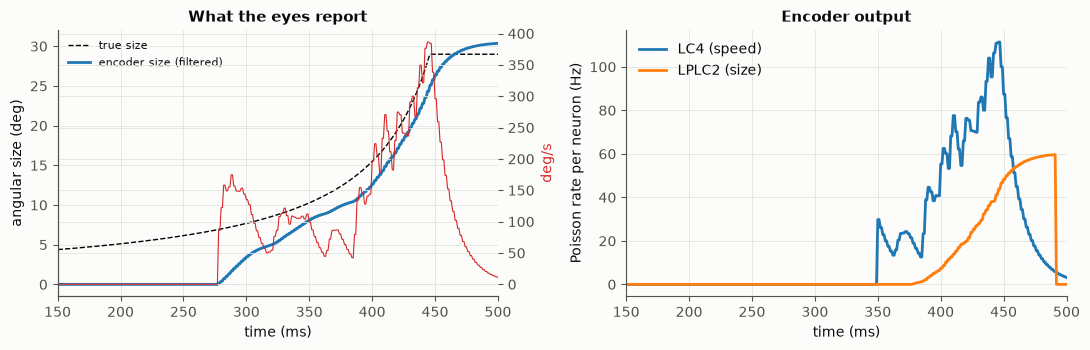

In [6]:
logs = p4.experiments(VARIANT, seeds=SEEDS, gif=FIGURES / f"phase4_escape_{VARIANT}.gif")
rec = logs["record"][0]
t = rec["t"]
true = 2 * np.degrees(np.arcsin(np.clip(2 / np.linalg.norm(rec["ball"] - rec["head"], axis=1), 0, 1)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t, true, "k--", lw=1, label="true size")
ax[0].plot(t, rec["theta"], label="encoder size (filtered)")
ax[0].set(xlabel="time (ms)", ylabel="angular size (deg)", title="What the eyes report")
ax0b = ax[0].twinx()
ax0b.plot(t, rec["velocity"], color="C3", lw=0.8, label="expansion speed")
ax0b.set_ylabel("deg/s", color="C3")
ax[0].legend(frameon=False, loc="upper left", fontsize=8)
ax[1].plot(t, rec["lc4"].mean(1), label="LC4 (speed)")
ax[1].plot(t, rec["lplc2"].mean(1), label="LPLC2 (size)")
ax[1].set(xlabel="time (ms)", ylabel="Poisson rate per neuron (Hz)", title="Encoder output")
ax[1].legend(frameon=False)
for a in ax:
    a.set_xlim(150, 500)
plt.tight_layout()
plt.savefig(FIGURES / "phase4_encoder.png", dpi=150)

LC4 switches on first, at 350 ms (ball ~8°), because expansion speed is already high while the ball is still small; LPLC2 follows 28 ms later, once the size passes its 10° threshold. When the ball stops (~450 ms) the expansion ends and both drop to (almost) zero, even though the ball is still large: neither cell type reports a big, still object.

## 3. The brain as a stepper: timing and latency

`simulate_torch` used to run a whole trial in one call, with the input fixed in advance. A loop
needs the brain to wait for the body, so the simulator's state now lives in a `LIFStepper`:

```python
brain = LIFStepper(W, drive=lplc2_lc4, n_trials=1, watch=escape_dns)
counts = brain.step(10, rate_hz=rates)     # advance 10 x 0.1 ms with these input rates
```

`simulate_torch` itself is now "make a stepper, step it once". The test suite checks that a run
cut into chunks of 1, 17, 18, 19, 21, 22, 23, 100, 779 and 1000 steps gives the same spikes and
voltages (float64, bit for bit) as the one-shot run, and every Phase 3 test still passes.

**Clocks.** Brain dt = 0.1 ms; flygym's physics timestep = 0.1 ms. They are equal, so the loop
exchanges messages every **control tick of 1 ms = 10 steps of each**, and the eyes are rendered
every 2 ms (500 Hz; fly photoreceptors follow flicker up to roughly 100–200 Hz). Within a tick
inputs and commands are held constant (zero-order hold). The command computed from tick k's DN
spikes is applied in tick k + 1, so the loop is strictly causal.

**Latency budget** from "the ball got bigger" to "the legs do something else":

In [7]:
budget = pd.DataFrame([
    ("vision frame", "≤ 2", "render period"),
    ("encoder low-pass", "~15", "tau of the size filter; speed lags by about tau"),
    ("brain: LPLC2/LC4 → first DN spike", "~5–10", "Phase 3: DNp04 first at 5.0–5.5 ms"),
    ("decoder rate filter", "~20", "tau of the DN rate estimate"),
    ("control tick (causality)", "≤ 1", "command applied one tick later"),
    ("CPG amplitude", "~50", "oscillator magnitudes converge at 20 /s"),
], columns=["stage", "ms", "why"])
budget

,stage,ms,why
0,vision frame,≤ 2,render period
1,encoder low-pass,~15,tau of the size filter; speed lags by about tau
2,brain: LPLC2/LC4 → first DN spike,~5–10,Phase 3: DNp04 first at 5.0–5.5 ms
3,decoder rate filter,~20,tau of the DN rate estimate
4,control tick (causality),≤ 1,command applied one tick later
5,CPG amplitude,~50,oscillator magnitudes converge at 20 /s


In [8]:
# last seed of each condition (seed 0 of "closed" also rendered the GIF, which is slower)
wall = pd.DataFrame({k: v[-1]["wall_s"] for k, v in logs.items() if "wall_s" in v[-1]},
                    index=["vision", "brain", "body"]).T
wall["total"] = wall.sum(axis=1)
wall["x slower than real time"] = (wall["total"] / (p4.T_RUN / 1000)).round(0)
wall.round(1)

,vision,brain,body,total,x slower than real time
record,26.4,0.0,9.2,35.6,36.0
no_brain,25.8,0.0,10.1,35.9,36.0
open,0.0,4.5,13.9,18.5,18.0
closed,39.4,6.8,15.9,62.2,62.0
closed_-LC4,69.3,6.9,16.0,92.1,92.0
closed_-LPLC2,67.2,5.8,15.0,88.0,88.0


Rendering the 1,442 ommatidia dominates the wall-clock time; the 134k-neuron brain at batch size 1 is the cheap part (open-loop runs, which skip the eyes, take a fraction of the time). Nothing here is real time. A robot would compute the two looming features directly from its camera instead of rendering a compound eye, and run only the subcircuit between LPLC2/LC4 and the DNs.

## 4. The decoder: DN spikes → walking command

Eight neurons are read: DNp01, DNp02, DNp04 and DNp11, left and right. Spike counts per tick are
smoothed into rates (τ = 20 ms). Then the assumptions (also in `c2c/control/decoder.py`):

| | assumption | basis |
|---|---|---|
| A1 | DNp02 + DNp04 → **backward** escape | co-activation gives backward jumps (Peek 2018; Dombrovski et al. 2023) |
| A2 | DNp11 → **forward** escape | activation gives forward jumps (same) |
| A3 | DNp01 (giant fiber) → **takeoff**: logged, not executed | the body is legs-only, it cannot fly |
| A4 | escape direction is expressed by walking | no takeoff controller in flygym |
| A5 | baseline: constant forward walking command | walking DNs are not stimulated here |
| A6 | programs mixed as a weighted average, walking weight 1, escape weight = rate / 40 Hz | one free number, output bounded |
| A7 | same command both sides (no turning) | the stimulus is frontal |

$$s = \frac{1 + x_{fwd}\,v_{fwd} - x_{back}\,v_{back}}{1 + x_{fwd} + x_{back}}, \qquad x = \frac{\text{rate}}{r_{50}}$$

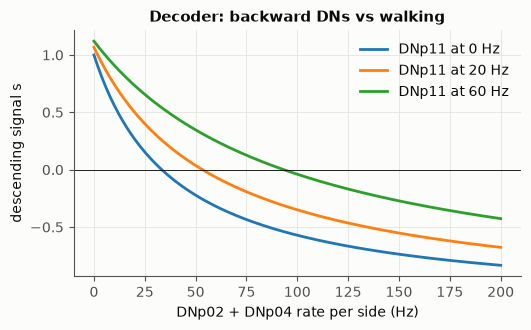

In [9]:
from c2c.control.decoder import EscapeDecoder

dec = EscapeDecoder([f"{t} {s}" for t in ["DNp01", "DNp04", "DNp02", "DNp11"] for s in "LR"])
r = np.linspace(0, 200, 201)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for fwd in [0, 20, 60]:
    s = [dec.command(np.array([0, 0, b / 2, b / 2, b / 2, b / 2, fwd, fwd], float))[0] for b in r]
    ax.plot(r, s, label=f"DNp11 at {fwd} Hz")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="DNp02 + DNp04 rate per side (Hz)", ylabel="descending signal s",
       title="Decoder: backward DNs vs walking")
ax.legend(frameon=False)
plt.tight_layout()

## 5. Experiments

### (a) Open loop: replay the looming stimulus

The brain receives the rate trace recorded from the standing fly (section 2), while the body is
free to walk. The body can react, but its movement cannot change the input: an experimenter's
playback, like a tethered-fly experiment with the legs free.

Baseline `no_brain`: same ball, brain disconnected, the fly keeps walking forward.

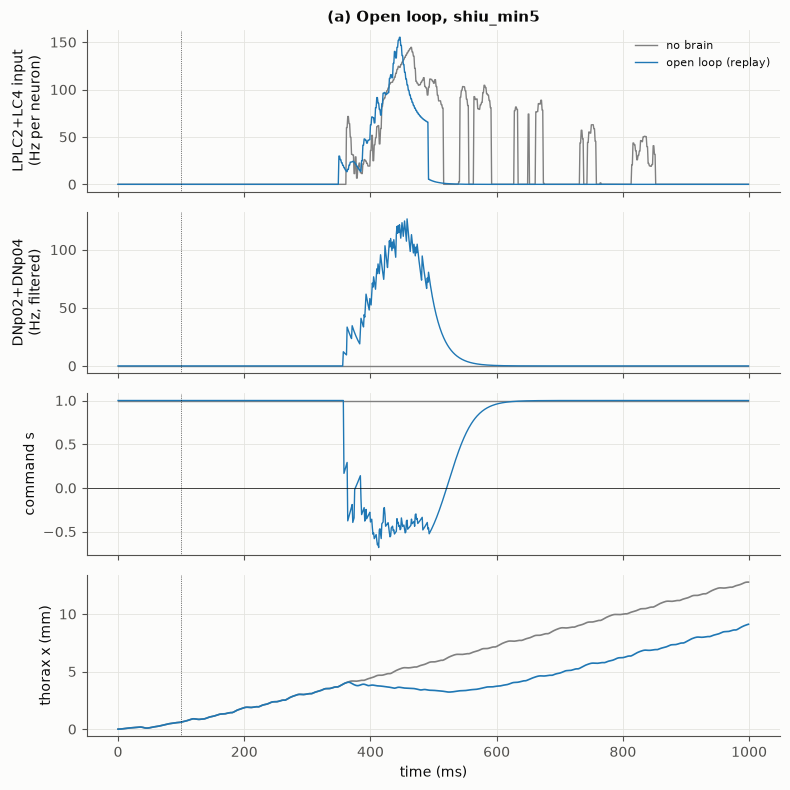

In [10]:
def plot_run(log, axes, label, color):
    t = log["t"]
    names = [str(n) for n in log["dn_names"]]
    back = [i for i, n in enumerate(names) if n.split()[0] in ("DNp02", "DNp04")]
    axes[0].plot(t, log["lc4"].mean(1) + log["lplc2"].mean(1), color=color, lw=1, label=label)
    axes[1].plot(t, log["dn_rates"][:, back].mean(1), color=color, lw=1)
    axes[2].plot(t, log["command"][:, 0], color=color, lw=1)
    axes[3].plot(t, log["thorax"][:, 0] - log["thorax"][0, 0], color=color, lw=1.2)


def compare(conds, title, fname):
    fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
    for (key, label), c in zip(conds, ["0.5", "C0", "C3", "C2", "C1"]):
        plot_run(logs[key][0], axes, label, c)
    axes[0].set(ylabel="LPLC2+LC4 input\n(Hz per neuron)", title=title)
    axes[1].set(ylabel="DNp02+DNp04\n(Hz, filtered)")
    axes[2].set(ylabel="command s")
    axes[2].axhline(0, color="k", lw=0.5)
    axes[3].set(ylabel="thorax x (mm)", xlabel="time (ms)")
    axes[0].legend(frameon=False, fontsize=8)
    for a in axes:
        a.axvline(p4.LOOM_ONSET, color="k", lw=0.5, ls=":")
    plt.tight_layout()
    plt.savefig(FIGURES / fname, dpi=150)


compare([("no_brain", "no brain"), ("open", "open loop (replay)")],
        f"(a) Open loop, {VARIANT}", f"phase4_open_loop_{VARIANT}.png")

In [11]:
def table(keys):
    rows = []
    for k in keys:
        for s, log in zip(SEEDS, logs[k]):
            rows.append({"condition": k, "seed": s, **p4.summary(log)})
    return pd.DataFrame(rows)


cols = ["condition", "seed", "cmd_latency_ms", "min_gap_mm", "standoff_gap_mm", "x_max_mm", "x_final_mm",
        "first DNp04 L", "first DNp02 L", "first DNp11 L", "spikes DNp01 L", "takeoff_ms"]
table(["no_brain", "open"])[cols].round(1)

,condition,seed,cmd_latency_ms,min_gap_mm,standoff_gap_mm,x_max_mm,x_final_mm,first DNp04 L,first DNp02 L,first DNp11 L,spikes DNp01 L,takeoff_ms
0,no_brain,0,NaN,1.3,2.7,12.8,12.8,NaN,NaN,NaN,0,NaN
1,open,0,14.0,1.4,1.9,9.1,9.1,8.0,14.0,25.0,9,408.0
2,open,1,13.0,0.7,1.3,9.4,9.4,13.0,25.0,29.0,10,408.0
3,open,2,13.0,0.8,1.4,9.4,9.4,10.0,15.0,22.0,10,417.0


With the brain disconnected the fly walks 12.8 mm forward and passes under the ball (closest gap 1.3 mm). With the replayed stimulus the brain backs it up 13–14 ms after the input starts, but once the recorded input ends (the ball stopped, so the standing fly saw nothing more expand) the command returns to walking and the fly walks on under the ball: 9.1–9.4 mm forward by the end, closest gap 0.7–1.4 mm. Open loop gets the reflex right and the follow-up wrong.

### (b) Closed loop: the fly sees the ball itself

Same ball, but now the encoder reads the live eyes every 2 ms. When the fly backs away, the ball's
image grows more slowly, so the brain's input depends on what the brain just did.

,condition,seed,cmd_latency_ms,min_gap_mm,standoff_gap_mm,x_max_mm,x_final_mm,first DNp04 L,first DNp02 L,first DNp11 L,spikes DNp01 L,takeoff_ms
0,closed,0,9.0,2.8,3.0,4.2,3.9,9.0,14.0,23.0,23,386.0
1,closed,1,15.0,3.0,3.3,4.1,3.3,12.0,22.0,22.0,35,386.0
2,closed,2,8.0,2.8,3.0,4.3,3.4,8.0,10.0,12.0,38,409.0


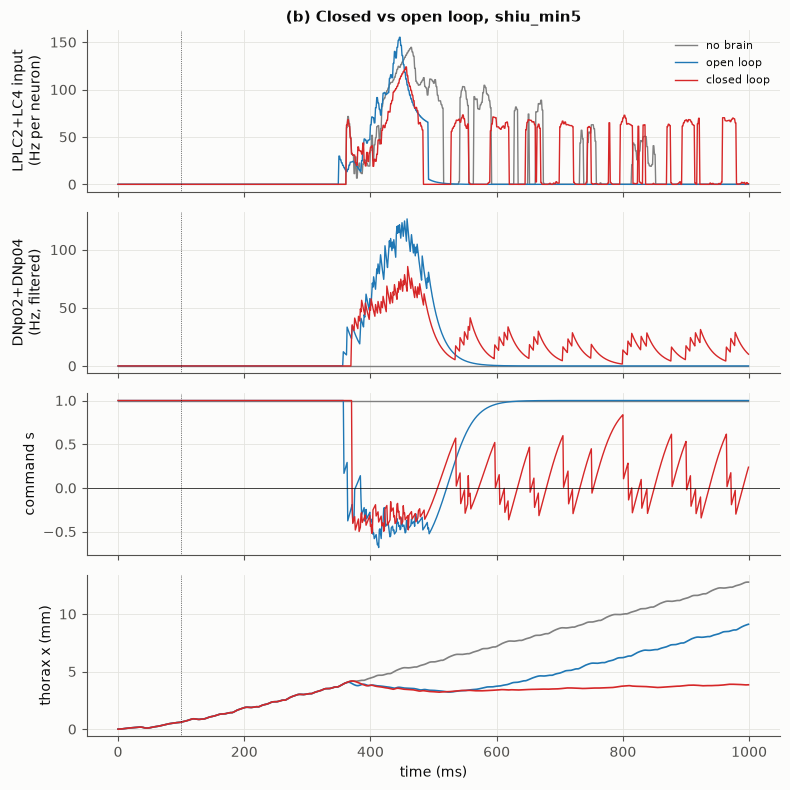

In [12]:
compare([("no_brain", "no brain"), ("open", "open loop"), ("closed", "closed loop")],
        f"(b) Closed vs open loop, {VARIANT}", f"phase4_closed_loop_{VARIANT}.png")
table(["closed"])[cols].round(1)

Closed loop, three seeds: the backward command starts 8–15 ms after the input, the same reflex as open loop. The difference comes after the ball stops. Every time the fly creeps forward, its own movement makes the ball expand on the retina, LPLC2 and DNp04 fire, and the command dips below zero again. The fly **holds a 3.0–3.3 mm gap for the last half second** and ends 3.3–3.9 mm from where it started, against 9.3 mm in open loop.

No line of code says "keep your distance". It is a set point that emerges from feedback: the gap settles where the brain's backward drive balances the tonic walking drive. In the standoff only DNp04 (and the giant fiber) stay active; DNp02 and DNp11 fall silent, because they need LC4 and the slow creeping barely drives it.

![closed-loop escape](../results/figures/phase4_escape_shiu_min5.gif)

### (c) Silencing: does Phase 3's prediction carry over to behaviour?

**Predictions written before the runs.** Phase 3 measured each DN under fixed input with LC4 or LPLC2 silenced. Pushing those rates through the decoder (next cell) gives the command each condition would produce at steady 50 or 100 Hz input. My two predictions from it:

1. The escape itself barely changes: the predicted command is −0.4 to −0.6 in all three conditions, because DNp04 survives both silencings and the decoder sums DNp02 + DNp04.
2. The standoff depends on LPLC2: creeping forward expands the ball slowly, which drives LPLC2 (size) far more than LC4 (speed). So −LPLC2 should let the fly drift closer, and −LC4 should not.

In [13]:
from c2c.analysis import phase3 as p3

out3, tr3, _, _ = p3.silencing(VARIANT)          # Phase 3 silencing, fixed Poisson input
dns3 = p3.network(VARIANT).escape()
dec3 = EscapeDecoder(list(dns3))
rows = []
for cond in ["intact", "-LC4", "-LPLC2"]:
    for hz in (50, 100):
        r = out3[cond].rates()[list(dns3.values())][:, tr3 == hz].mean(1)
        p = dec3.program_drive(r)
        rows.append({"condition": cond, "input_hz": hz, "x_back": p["x_back"], "x_fwd": p["x_fwd"],
                     "predicted command s": dec3.command(r)[0], "takeoff trigger": p["takeoff"]})
pd.DataFrame(rows).round(2)

,condition,input_hz,x_back,x_fwd,predicted command s,takeoff trigger
0,intact,50,4.76,1.28,-0.45,True
1,intact,100,7.11,2.18,-0.48,True
2,-LC4,50,1.80,0.00,-0.41,True
3,-LC4,100,2.89,0.00,-0.63,True
4,-LPLC2,50,4.45,1.29,-0.41,True
5,-LPLC2,100,6.56,2.22,-0.43,True


Both silencings still trigger the takeoff flag at steady input, and the backward command stays negative. Now the closed loop:

,condition,seed,cmd_latency_ms,min_gap_mm,standoff_gap_mm,x_max_mm,x_final_mm,first DNp04 L,first DNp02 L,first DNp11 L,spikes DNp01 L,takeoff_ms
0,closed,0,9.0,2.8,3.0,4.2,3.9,9.0,14.0,23.0,23,386.0
1,closed,1,15.0,3.0,3.3,4.1,3.3,12.0,22.0,22.0,35,386.0
2,closed,2,8.0,2.8,3.0,4.3,3.4,8.0,10.0,12.0,38,409.0
3,closed_-LC4,0,74.0,1.9,2.0,5.4,5.3,NaN,NaN,NaN,28,426.0
4,closed_-LC4,1,88.0,1.8,2.1,5.1,4.5,88.0,NaN,NaN,38,406.0
5,closed_-LC4,2,53.0,1.8,1.9,5.0,4.9,53.0,NaN,NaN,37,416.0
6,closed_-LPLC2,0,9.0,1.9,2.4,5.4,5.3,9.0,13.0,22.0,0,398.0
7,closed_-LPLC2,1,15.0,2.3,2.5,4.3,4.3,12.0,22.0,22.0,9,399.0
8,closed_-LPLC2,2,8.0,2.1,2.4,4.6,4.5,8.0,10.0,12.0,9,412.0


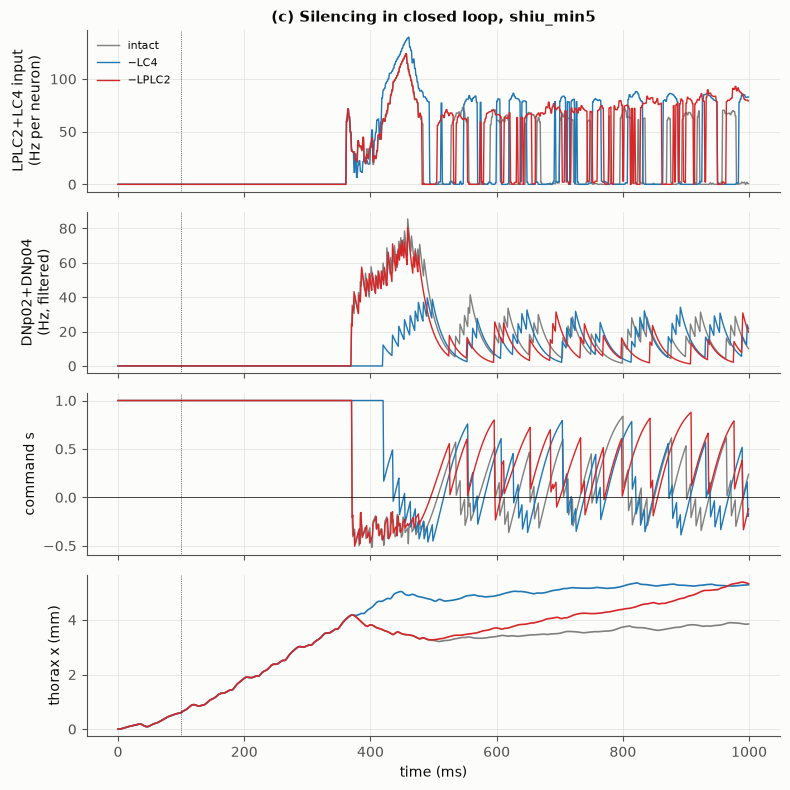

In [14]:
compare([("closed", "intact"), ("closed_-LC4", "−LC4"), ("closed_-LPLC2", "−LPLC2")],
        f"(c) Silencing in closed loop, {VARIANT}", f"phase4_silencing_{VARIANT}.png")
sil = table(["closed", "closed_-LC4", "closed_-LPLC2"])
sil[cols].round(1)

In [15]:
sil["giant fiber spikes"] = sil["spikes DNp01 L"] + sil["spikes DNp01 R"]
sil.groupby("condition", sort=False)[["cmd_latency_ms", "min_gap_mm", "standoff_gap_mm", "x_final_mm",
                                      "giant fiber spikes",
                                      "spikes DNp04 L", "spikes DNp02 L", "spikes DNp11 L"]
                                     ].agg(["mean", "std"]).round(1)

cmd_latency_ms       min_gap_mm      standoff_gap_mm       \
                        mean   std       mean  std            mean  std   
condition                                                                 
closed                  10.7   3.8        2.8  0.1             3.1  0.2   
closed_-LC4             71.7  17.6        1.8  0.0             2.0  0.1   
closed_-LPLC2           10.7   3.8        2.1  0.2             2.5  0.1   

              x_final_mm      giant fiber spikes      spikes DNp04 L        \
                    mean  std               mean  std           mean   std   
condition                                                                    
closed               3.5  0.3               79.0  4.6           32.0  26.0   
closed_-LC4          4.9  0.4               76.7  2.1           22.7  19.9   
closed_-LPLC2        4.7  0.5               14.7  4.0           25.7  20.5   

              spikes DNp02 L       spikes DNp11 L        
                        mean   std           mean   std  
condition                                                
closed                   8.7   6.7            9.3   7.2  
closed_-LC4              0.0   0.0            0.0   0.0  
closed_-LPLC2           13.3  10.8           13.3  10.7

**Both predictions were wrong, and the way they were wrong is the interesting part.**

- **−LC4 delays the escape by about 60 ms** (backward command 53–88 ms after the input, against 8–15 ms intact) and the fly ends up 1.8 mm from the ball instead of 2.8. The steady-input table missed this because the start of a real approach is not steady: speed grows before size, so for the first ~30 ms LC4 is the only channel with any input. LC4 is the early-warning channel.
- **−LPLC2 leaves the escape onset exactly as intact** (same ticks, same seeds: the first DN spikes come from LC4 alone) **but removes 81% of the giant fiber's spikes** (15 vs 79). That is Ache et al.'s finding that LPLC2 is necessary for giant-fiber escape, reproduced from the wiring alone.
- **Both shrink the standoff** (2.0 mm without LC4, 2.4 mm without LPLC2, 3.0–3.3 intact). In feedback terms, silencing lowers the gain from looming to backward drive, so the loop must see a bigger, faster-growing ball before it balances, and the set point moves closer.

A double dissociation: LC4 sets *when* the walking escape starts, LPLC2 decides whether the *giant fiber* fires. Neither shows up in the steady-input Phase 3 table; both need a body in a loop.

## Takeaways

- **Which connectome:** the ≥ 5-synapse threshold is harmless for escape; one sign per neuron vs one per edge decides whether the giant fiber fires. Phase 4 uses `shiu_min5`.
- **The loop works:** looming → LPLC2/LC4 → 134k spiking neurons → DNp04 first, then DNp02/DNp11 → backward walking, 8–15 ms from input to command.
- **Closed loop does something open loop cannot:** after the ball stops, the fly holds a ~3 mm gap for half a second, a set point that emerges from its own movement feeding back into its eyes.
- **Silencing in a loop separates roles a fixed-input experiment blurs:** LC4 is the early warning (−60 ms without it), LPLC2 drives the giant fiber (−81% without it).
- **Engineering:** filters, not neurons, dominate latency; rendering the eyes, not the brain, dominates compute.